# Notebook 00 - Initial setup

In [19]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime.executor_sampler import Sampler

# loads IBM backend service
service = QiskitRuntimeService() 

In [20]:
for b in service.backends():
    print(b.name, b.num_qubits, "qubits")

backend = service.least_busy(operational=True, simulator=False)
print("least busy:", backend.name)

ibm_boston 156 qubits
ibm_fez 156 qubits
ibm_kingston 156 qubits
ibm_marrakesh 156 qubits
ibm_phoenix 120 qubits
ibm_pittsburgh 156 qubits
least busy: ibm_marrakesh


Test circuit

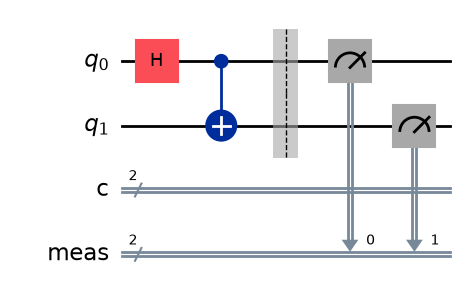

In [21]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)

qc.measure_all()
qc.draw("mpl")

Run implementation on Aer Simulator

{'11': 485, '00': 515}


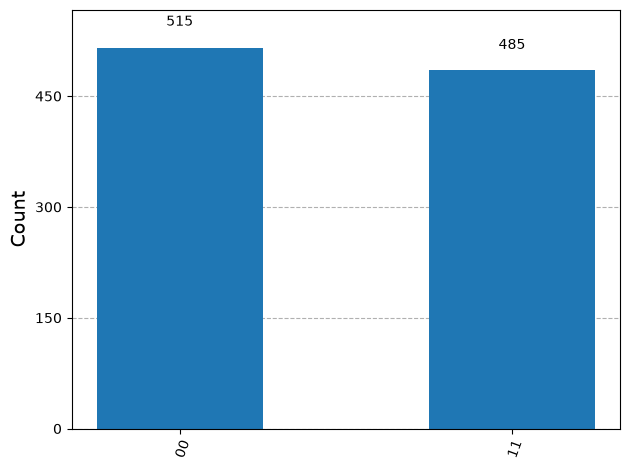

In [22]:
# transpiler
sim = AerSimulator()
pm = generate_preset_pass_manager(backend=sim, optimization_level=1)
isa_qc = pm.run(qc)

# sampler
sampler = Sampler(mode=sim)
job = sampler.run([isa_qc], shots=1000)
result = job.result()

# results
counts = result[0].data.meas.get_counts()
print(counts)
plot_histogram(counts)

QPU implementation

In [ ]:
raise RuntimeError("This cell creates/submits IBM quantum jobs. Do not re-run")

backend = service.least_busy(operational=True, simulator=False)

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_qc = pm.run(qc)

sampler = Sampler(mode=backend)
job = sampler.run([isa_qc], shots=1000)
print(job.job_id())

About 6.9% of the shots gave 01 and 10 outcomes, that are impossible from an ideal Bell state

The errors come mainly from **readout errors** 

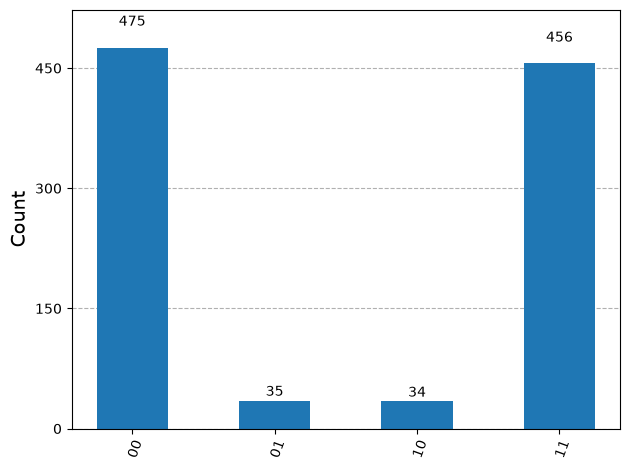

In [ ]:
job = service.job("dbd7dt7i0auc7394s3lg")

print("Backend:", job.backend().name)
print("Data:", job.creation_date)
print("QPU time:", job.usage(), "seconds")

counts = job.result()[0].data.meas.get_counts()
errors = counts.get("01", 0) + counts.get("10", 0)
plot_histogram(counts)